Step 2

In [ ]:

from google.colab import files
uploaded = files.upload()

Saving student_dropout_dataset_v3.csv to student_dropout_dataset_v3.csv


In [ ]:
import pandas as pd
df=pd.read_csv("student_dropout_dataset_v3.csv")
df.head()

,Student_ID,Age,Gender,Family_Income,Internet_Access,Study_Hours_per_Day,Attendance_Rate,Assignment_Delay_Days,Travel_Time_Minutes,Part_Time_Job,Scholarship,Stress_Index,GPA,Semester_GPA,CGPA,Semester,Department,Parental_Education,Dropout
0,1,22.1,Male,25000.0,Yes,3.36,86.1,2,20.4,Yes,No,5.5,0.96,0.90,0.90,Year 1,Arts,High School,0
1,2,20.7,Male,25000.0,Yes,4.30,68.0,2,44.0,No,No,6.8,1.28,1.20,1.19,Year 3,Engineering,Bachelor,1
2,3,22.4,Male,40183.0,Yes,4.40,70.9,0,48.9,Yes,No,5.5,1.68,1.32,1.32,Year 1,Arts,Master,0
3,4,24.4,Male,NaN,Yes,NaN,82.2,2,38.6,No,No,NaN,1.78,1.77,1.77,Year 1,CS,High School,1
4,5,20.5,Female,25319.0,Yes,4.19,75.7,1,23.0,No,No,7.0,1.48,0.91,0.87,Year 4,Business,Bachelor,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 19 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Student_ID             10000 non-null  int64  
 1   Age                    10000 non-null  float64
 2   Gender                 10000 non-null  object 
 3   Family_Income          9500 non-null   float64
 4   Internet_Access        10000 non-null  object 
 5   Study_Hours_per_Day    9500 non-null   float64
 6   Attendance_Rate        10000 non-null  float64
 7   Assignment_Delay_Days  10000 non-null  int64  
 8   Travel_Time_Minutes    10000 non-null  float64
 9   Part_Time_Job          10000 non-null  object 
 10  Scholarship            10000 non-null  object 
 11  Stress_Index           9500 non-null   float64
 12  GPA                    10000 non-null  float64
 13  Semester_GPA           10000 non-null  float64
 14  CGPA                   10000 non-null  float64
 15  Sem

In [ ]:
df.shape

(10000, 19)

In [ ]:
df.dtypes

,0
Student_ID,int64
Age,float64
Gender,object
Family_Income,float64
Internet_Access,object
Study_Hours_per_Day,float64
Attendance_Rate,float64
Assignment_Delay_Days,int64
Travel_Time_Minutes,float64
Part_Time_Job,object


In [ ]:
df.describe()

,Student_ID,Age,Family_Income,Study_Hours_per_Day,Attendance_Rate,Assignment_Delay_Days,Travel_Time_Minutes,Stress_Index,GPA,Semester_GPA,CGPA,Dropout
count,10000.00000,10000.00000,9500.000000,9500.000000,10000.00000,10000.000000,10000.00000,9500.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,21.02606,38377.247474,4.014592,81.73683,1.799700,30.17926,5.507147,2.308440,2.300057,2.298761,0.23540
std,2886.89568,2.13981,20496.232179,1.295450,8.22093,1.344307,11.91887,1.765951,1.061717,1.074407,1.072555,0.42427
min,1.00000,17.00000,25000.000000,0.500000,38.20000,0.000000,5.00000,1.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,19.50000,25000.000000,3.160000,76.40000,1.000000,21.90000,4.300000,1.550000,1.520000,1.520000,0.00000
50%,5000.50000,21.00000,29740.500000,4.000000,81.80000,2.000000,30.20000,5.500000,2.350000,2.350000,2.350000,0.00000
75%,7500.25000,22.50000,44520.000000,4.870000,87.30000,3.000000,38.40000,6.700000,3.120000,3.150000,3.150000,0.00000
max,10000.00000,29.60000,316601.000000,8.980000,100.00000,8.000000,74.90000,10.000000,4.000000,4.000000,4.000000,1.00000


In [ ]:
df.isnull().sum()

,0
Student_ID,0
Age,0
Gender,0
Family_Income,500
Internet_Access,0
Study_Hours_per_Day,500
Attendance_Rate,0
Assignment_Delay_Days,0
Travel_Time_Minutes,0
Part_Time_Job,0


In [ ]:
(df.isnull().mean() * 100).round(2)

,0
Student_ID,0.00
Age,0.00
Gender,0.00
Family_Income,5.00
Internet_Access,0.00
Study_Hours_per_Day,5.00
Attendance_Rate,0.00
Assignment_Delay_Days,0.00
Travel_Time_Minutes,0.00
Part_Time_Job,0.00


In [ ]:
#for finding the duplicate rows
df.duplicated().sum()

np.int64(0)

In [ ]:
!pip install sweetviz -q
import sweetviz as sv
from google.colab import files

report = sv.analyze(df)
report.show_html("sweetviz_report.html")
files.download("sweetviz_report.html")

                                             |          | [  0%]   00:00 -> (? left)

Report sweetviz_report.html was generated! NOTEBOOK/COLAB USERS: the web browser MAY not pop up, regardless, the report IS saved in your notebook/colab files.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

step 3

In [ ]:
# working copy
df_manual = df.copy()
print(df_manual.shape)

(10000, 19)


In [ ]:
df_manual["Semester"].value_counts()

,count
Semester,
Year 4,2536
Year 3,2521
Year 2,2488
Year 1,2455


In [ ]:
#renaming semester column as year_of_study
df_manual = df_manual.rename(columns={"Semester": "Year_of_Study"})
df_manual["Year_of_Study"].value_counts()


,count
Year_of_Study,
Year 4,2536
Year 3,2521
Year 2,2488
Year 1,2455


In [ ]:
df_manual.dtypes

,0
Student_ID,int64
Age,float64
Gender,object
Family_Income,float64
Internet_Access,object
Study_Hours_per_Day,float64
Attendance_Rate,float64
Assignment_Delay_Days,int64
Travel_Time_Minutes,float64
Part_Time_Job,object


In [ ]:
df_manual.isnull().sum()

,0
Student_ID,0
Age,0
Gender,0
Family_Income,500
Internet_Access,0
Study_Hours_per_Day,500
Attendance_Rate,0
Assignment_Delay_Days,0
Travel_Time_Minutes,0
Part_Time_Job,0


In [ ]:
# filling the numerical columns with median
for col in ["Family_Income", "Study_Hours_per_Day", "Stress_Index"]:
    df_manual[col] = df_manual[col].fillna(df_manual[col].median())

df_manual[["Family_Income", "Study_Hours_per_Day", "Stress_Index"]].isnull().sum()

,0
Family_Income,0
Study_Hours_per_Day,0
Stress_Index,0


In [ ]:
# filling parental_education with mode
mode_value = df_manual["Parental_Education"].mode()[0]
print("Most frequent value:", mode_value)

df_manual["Parental_Education"] = df_manual["Parental_Education"].fillna(mode_value)
df_manual.isnull().sum().sum()

Most frequent value: Bachelor


np.int64(0)

In [ ]:
# outlier check for family income
Q1 = df_manual["Family_Income"].quantile(0.25)
Q3 = df_manual["Family_Income"].quantile(0.75)
IQR = Q3 - Q1
low = Q1 - 1.5 * IQR
high = Q3 + 1.5 * IQR
count = ((df_manual["Family_Income"] < low) | (df_manual["Family_Income"] > high)).sum()

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Valid range:", low, "to", high)
print("Outliers:", count)

Q1: 25000.0
Q3: 43361.75
IQR: 18361.75
Valid range: -2542.625 to 70904.375
Outliers: 683


In [ ]:
df_manual["Family_Income"] = df_manual["Family_Income"].clip(upper=high)

print("New maximum:", df_manual["Family_Income"].max())
print("Rows:", df_manual.shape[0])

New maximum: 70904.375
Rows: 10000


In [ ]:
# checking for outliers in other numeric columns
import pandas as pd
import os

# Fallback search for any available dataset in the workspace
if 'df_manual' not in locals():
    possible_files = [
        "cleaned_student_dropout (1).csv",
        "cleaned_student_dropout.csv",
        "student_dropout_dataset_v3.csv"
    ]
    found_file = None
    for f in possible_files:
        if os.path.exists(f):
            found_file = f
            break

    if found_file:
        print(f"Loading data from local file: {found_file}")
        df_manual = pd.read_csv(found_file)
    elif 'df' in locals():
        df_manual = df.copy()
    else:
        raise FileNotFoundError("Neither the variables ('df_manual' or 'df') nor the files ('cleaned_student_dropout (1).csv' or 'student_dropout_dataset_v3.csv') are present. Please scroll up and re-run the file upload cell first (e.g., cell DRIgzU09UkTf) to restore the session.")

cols = ["Age", "Study_Hours_per_Day", "Attendance_Rate", "Assignment_Delay_Days",
        "Travel_Time_Minutes", "Stress_Index", "GPA", "Semester_GPA", "CGPA"]

for col in cols:
    # Temporarily fill NaNs with median for the IQR calculations
    temp_col = df_manual[col].fillna(df_manual[col].median())
    Q1 = temp_col.quantile(0.25)
    Q3 = temp_col.quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    count = ((temp_col < lower) | (temp_col > upper)).sum()
    print(f"{col}: {count} outliers (valid range {lower:.2f} to {upper:.2f})")

Age: 33 outliers (valid range 15.00 to 27.00)
Study_Hours_per_Day: 138 outliers (valid range 0.81 to 7.21)
Attendance_Rate: 57 outliers (valid range 60.05 to 103.65)
Assignment_Delay_Days: 25 outliers (valid range -2.00 to 6.00)
Travel_Time_Minutes: 25 outliers (valid range -2.85 to 63.15)
Stress_Index: 137 outliers (valid range 1.10 to 9.90)
GPA: 0 outliers (valid range -0.80 to 5.47)
Semester_GPA: 0 outliers (valid range -0.92 to 5.59)
CGPA: 0 outliers (valid range -0.92 to 5.59)


In [ ]:
# AI powered ML algorithm
from sklearn.ensemble import IsolationForest

features = ["Age", "Family_Income", "Study_Hours_per_Day", "Attendance_Rate",
            "Assignment_Delay_Days", "Travel_Time_Minutes", "Stress_Index",
            "GPA", "Semester_GPA", "CGPA"]

model = IsolationForest(contamination=0.05, random_state=42)
labels = model.fit_predict(df_manual[features])

print(pd.Series(labels).value_counts())

 1    9500
-1     500
Name: count, dtype: int64


In [ ]:
# compare isolation forest with iqr
cols = ["Age", "Study_Hours_per_Day", "Attendance_Rate", "Assignment_Delay_Days",
        "Travel_Time_Minutes", "Stress_Index", "GPA", "Semester_GPA", "CGPA"]

iqr_flag = pd.Series(False, index=df_manual.index)
for col in cols:
    Q1 = df_manual[col].quantile(0.25)
    Q3 = df_manual[col].quantile(0.75)
    IQR = Q3 - Q1
    iqr_flag = iqr_flag | (df_manual[col] < Q1 - 1.5 * IQR) | (df_manual[col] > Q3 + 1.5 * IQR)

iso_flag = pd.Series(labels == -1, index=df_manual.index)

print("Flagged by Isolation Forest:", iso_flag.sum())
print("Flagged by IQR (any column):", iqr_flag.sum())
print("Flagged by both:", (iso_flag & iqr_flag).sum())
print("Only Isolation Forest:", (iso_flag & ~iqr_flag).sum())
print("Only IQR:", (~iso_flag & iqr_flag).sum())

Flagged by Isolation Forest: 500
Flagged by IQR (any column): 414
Flagged by both: 89
Only Isolation Forest: 411
Only IQR: 325


categorical encoding

In [ ]:
df_encoded = df_manual.copy()

text_cols = df_encoded.select_dtypes(include="object").columns
for col in text_cols:
    print(col, "->", list(df_encoded[col].unique()))

Gender -> ['Male', 'Female']
Internet_Access -> ['Yes', 'No']
Part_Time_Job -> ['Yes', 'No']
Scholarship -> ['No', 'Yes']
Year_of_Study -> ['Year 1', 'Year 3', 'Year 4', 'Year 2']
Department -> ['Arts', 'Engineering', 'CS', 'Business', 'Science']
Parental_Education -> ['High School', 'Bachelor', 'Master', 'PhD']


In [ ]:
df_manual = df_manual.rename(columns={"Semester": "Year_of_Study"})
df_encoded = df_encoded.rename(columns={"Semester": "Year_of_Study"})

print(df_encoded["Year_of_Study"].unique())

['Year 1' 'Year 3' 'Year 4' 'Year 2']


In [ ]:
#encode Gender, Internet_Access, Part_Time_Job and Scholarship
df_encoded["Gender"] = df_encoded["Gender"].map({"Male": 0, "Female": 1})

for col in ["Internet_Access", "Part_Time_Job", "Scholarship"]:
    df_encoded[col] = df_encoded[col].map({"No": 0, "Yes": 1})

df_encoded[["Gender", "Internet_Access", "Part_Time_Job", "Scholarship"]].head()

,Gender,Internet_Access,Part_Time_Job,Scholarship
0,0,1,1,0
1,0,1,0,0
2,0,1,1,0
3,0,1,0,0
4,1,1,0,0


In [ ]:
#encode Parental_Education and Year_of_Study
df_encoded["Parental_Education"] = df_encoded["Parental_Education"].map(
    {"High School": 0, "Bachelor": 1, "Master": 2, "PhD": 3})

df_encoded["Year_of_Study"] = df_encoded["Year_of_Study"].map(
    {"Year 1": 1, "Year 2": 2, "Year 3": 3, "Year 4": 4})

df_encoded[["Parental_Education", "Year_of_Study"]].head()

,Parental_Education,Year_of_Study
0,0,1
1,1,3
2,2,1
3,0,1
4,1,4


In [ ]:
#one-hot encode Department
df_encoded = pd.get_dummies(df_encoded, columns=["Department"], dtype=int)

print(df_encoded.shape)
print(df_encoded.select_dtypes(include="object").columns.tolist())
df_encoded.filter(like="Department").head()

(10000, 23)
[]


,Department_Arts,Department_Business,Department_CS,Department_Engineering,Department_Science
0,1,0,0,0,0
1,0,0,0,1,0
2,1,0,0,0,0
3,0,0,1,0,0
4,0,1,0,0,0


In [ ]:
#standardize the numeric columns
from sklearn.preprocessing import StandardScaler

df_scaled = df_encoded.copy()

scale_cols = ["Age", "Family_Income", "Study_Hours_per_Day", "Attendance_Rate",
              "Assignment_Delay_Days", "Travel_Time_Minutes", "Stress_Index",
              "GPA", "Semester_GPA", "CGPA"]

df_scaled[scale_cols] = StandardScaler().fit_transform(df_scaled[scale_cols])

print(df_scaled[scale_cols].mean().round(2))
print(df_scaled[scale_cols].std().round(2))

Age                      0.0
Family_Income            0.0
Study_Hours_per_Day      0.0
Attendance_Rate          0.0
Assignment_Delay_Days   -0.0
Travel_Time_Minutes      0.0
Stress_Index            -0.0
GPA                     -0.0
Semester_GPA             0.0
CGPA                    -0.0
dtype: float64
Age                      1.0
Family_Income            1.0
Study_Hours_per_Day      1.0
Attendance_Rate          1.0
Assignment_Delay_Days    1.0
Travel_Time_Minutes      1.0
Stress_Index             1.0
GPA                      1.0
Semester_GPA             1.0
CGPA                     1.0
dtype: float64


In [ ]:
#save and download the cleaned datasets
from google.colab import files

df_manual.to_csv("cleaned_student_dropout.csv", index=False)
df_scaled.to_csv("cleaned_student_dropout_scaled.csv", index=False)

files.download("cleaned_student_dropout.csv")
files.download("cleaned_student_dropout_scaled.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
#descriptive statistics for the numeric columns
df_manual[["Age", "Family_Income", "Study_Hours_per_Day", "Attendance_Rate",
           "Assignment_Delay_Days", "Travel_Time_Minutes", "Stress_Index",
           "GPA", "Semester_GPA", "CGPA"]].describe().round(2)

,Age,Family_Income,Study_Hours_per_Day,Attendance_Rate,Assignment_Delay_Days,Travel_Time_Minutes,Stress_Index,GPA,Semester_GPA,CGPA
count,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00
mean,21.03,36340.99,4.01,81.74,1.80,30.18,5.51,2.31,2.30,2.30
std,2.14,14546.81,1.26,8.22,1.34,11.92,1.72,1.06,1.07,1.07
min,17.00,25000.00,0.50,38.20,0.00,5.00,1.00,0.00,0.00,0.00
25%,19.50,25000.00,3.21,76.40,1.00,21.90,4.40,1.55,1.52,1.52
50%,21.00,29740.50,4.00,81.80,2.00,30.20,5.50,2.35,2.35,2.35
75%,22.50,43361.75,4.81,87.30,3.00,38.40,6.60,3.12,3.15,3.15
max,29.60,70904.38,8.98,100.00,8.00,74.90,10.00,4.00,4.00,4.00


In [ ]:
#dropout rate by gender
df_manual.groupby("Gender")["Dropout"].mean().round(3)

,Dropout
Gender,
Female,0.238
Male,0.232


In [ ]:
#dropout rate by department
df_manual.groupby("Department")["Dropout"].mean().round(3)

,Dropout
Department,
Arts,0.239
Business,0.233
CS,0.234
Engineering,0.240
Science,0.230


In [ ]:
#average of key columns for dropout vs non-dropout students
df_manual.groupby("Dropout")[["GPA", "Stress_Index", "Attendance_Rate",
                              "Study_Hours_per_Day", "Assignment_Delay_Days"]].mean().round(2)

,GPA,Stress_Index,Attendance_Rate,Study_Hours_per_Day,Assignment_Delay_Days
Dropout,,,,,
0,2.58,5.27,82.48,4.07,1.74
1,1.43,6.28,79.31,3.82,2.00


In [ ]:
#create an attendance level column
df_manual["Attendance_Level"] = pd.cut(df_manual["Attendance_Rate"],
                                       bins=[0, 75, 85, 100],
                                       labels=["Low", "Medium", "High"])

df_manual["Attendance_Level"].value_counts()

,count
Attendance_Level,
Medium,4516
High,3441
Low,2043


In [ ]:
#filter low-attendance, low-GPA students
risk = df_manual[(df_manual["Attendance_Level"] == "Low") & (df_manual["GPA"] < 1.5)]

print("Students selected:", len(risk))
print("Dropout rate in this group:", round(risk["Dropout"].mean(), 3))

Students selected: 666
Dropout rate in this group: 0.632


In [ ]:
#correlation matrix
cols = ["Age", "Family_Income", "Study_Hours_per_Day", "Attendance_Rate",
        "Assignment_Delay_Days", "Travel_Time_Minutes", "Stress_Index",
        "GPA", "Semester_GPA", "CGPA", "Dropout"]

df_manual[cols].corr().round(2)

,Age,Family_Income,Study_Hours_per_Day,Attendance_Rate,Assignment_Delay_Days,Travel_Time_Minutes,Stress_Index,GPA,Semester_GPA,CGPA,Dropout
Age,1.00,0.00,0.00,0.01,0.01,-0.01,-0.02,-0.01,-0.01,-0.01,0.01
Family_Income,0.00,1.00,-0.00,0.00,0.00,0.02,-0.02,0.00,0.01,0.00,-0.01
Study_Hours_per_Day,0.00,-0.00,1.00,-0.01,0.00,0.01,0.01,0.21,0.20,0.20,-0.09
Attendance_Rate,0.01,0.00,-0.01,1.00,-0.01,0.02,-0.01,0.21,0.20,0.20,-0.16
Assignment_Delay_Days,0.01,0.00,0.00,-0.01,1.00,-0.00,0.01,-0.03,-0.02,-0.02,0.08
Travel_Time_Minutes,-0.01,0.02,0.01,0.02,-0.00,1.00,0.00,0.01,0.01,0.01,0.03
Stress_Index,-0.02,-0.02,0.01,-0.01,0.01,0.00,1.00,-0.38,-0.36,-0.36,0.25
GPA,-0.01,0.00,0.21,0.21,-0.03,0.01,-0.38,1.00,0.96,0.96,-0.46
Semester_GPA,-0.01,0.01,0.20,0.20,-0.02,0.01,-0.36,0.96,1.00,1.00,-0.45
CGPA,-0.01,0.00,0.20,0.20,-0.02,0.01,-0.36,0.96,1.00,1.00,-0.44


In [ ]:
#one-way ANOVA of GPA by Attendance_Level
import statsmodels.api as sm
from statsmodels.formula.api import ols

lm = ols('GPA ~ Attendance_Level', data=df_manual).fit()
table = sm.stats.anova_lm(lm)
print(table)


                      df        sum_sq     mean_sq           F        PR(>F)
Attendance_Level     2.0    424.905307  212.452654  195.815321  3.819138e-84
Residual          9997.0  10846.389157    1.084964         NaN           NaN


In [ ]:
#average GPA for each attendance level
df_manual.groupby("Attendance_Level")["GPA"].mean().round(2)

/tmp/ipykernel_935/358656021.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_manual.groupby("Attendance_Level")["GPA"].mean().round(2)


,GPA
Attendance_Level,
Low,2.00
Medium,2.26
High,2.56


In [ ]:
#Stress_Index vs Dropout correlation on the original data
df[["Stress_Index", "Dropout"]].corr().round(3)

,Stress_Index,Dropout
Stress_Index,1.000,0.256
Dropout,0.256,1.000


step 4

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files

uploaded = files.upload()
df_manual = pd.read_csv(list(uploaded.keys())[0])

if "Attendance_Level" not in df_manual.columns:
    df_manual["Attendance_Level"] = pd.cut(df_manual["Attendance_Rate"],
                                           bins=[0, 75, 85, 100],
                                           labels=["Low", "Medium", "High"])

print(df_manual.shape)
print(df_manual.columns.tolist())

Saving cleaned_student_dropout (1).csv to cleaned_student_dropout (1).csv
(10000, 20)
['Student_ID', 'Age', 'Gender', 'Family_Income', 'Internet_Access', 'Study_Hours_per_Day', 'Attendance_Rate', 'Assignment_Delay_Days', 'Travel_Time_Minutes', 'Part_Time_Job', 'Scholarship', 'Stress_Index', 'GPA', 'Semester_GPA', 'CGPA', 'Year_of_Study', 'Department', 'Parental_Education', 'Dropout', 'Attendance_Level']


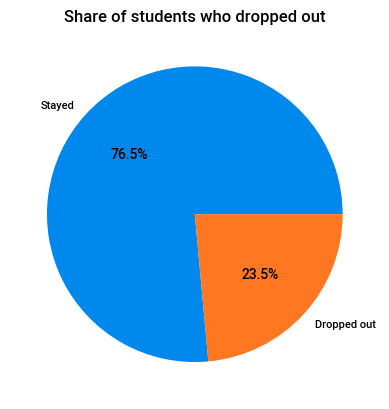

In [ ]:
#What share of students drop out?

# pie chart of dropout share
import matplotlib.pyplot as plt

counts = df_manual["Dropout"].value_counts().sort_index()

plt.pie(counts, labels=["Stayed", "Dropped out"], autopct="%1.1f%%")
plt.title("Share of students who dropped out")
plt.show()

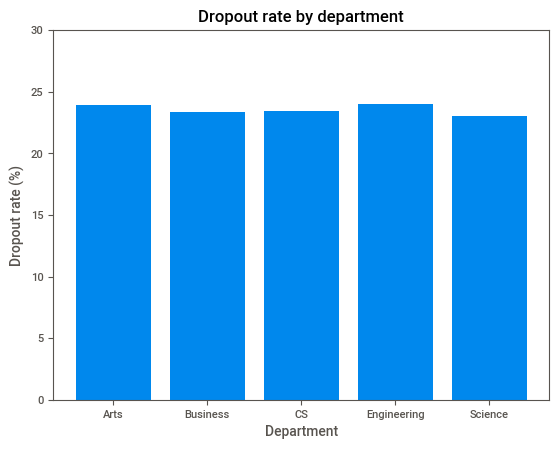

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
#Does dropout differ by department?
#bar chart of dropout rate by department
from google.colab import files

dept = df_manual.groupby("Department")["Dropout"].mean() * 100

plt.bar(dept.index, dept.values)
plt.title("Dropout rate by department")
plt.xlabel("Department")
plt.ylabel("Dropout rate (%)")
plt.ylim(0, 30)
plt.savefig("q2_bar_department.png")
plt.show()

files.download("q2_bar_department.png")

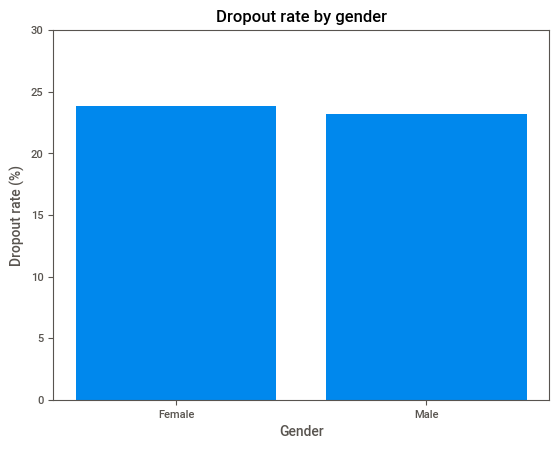

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
#bar chart of dropout rate by gender
gender = df_manual.groupby("Gender")["Dropout"].mean() * 100

plt.bar(gender.index, gender.values)
plt.title("Dropout rate by gender")
plt.xlabel("Gender")
plt.ylabel("Dropout rate (%)")
plt.ylim(0, 30)
plt.savefig("q2_bar_gender.png")
plt.show()

files.download("q2_bar_gender.png")

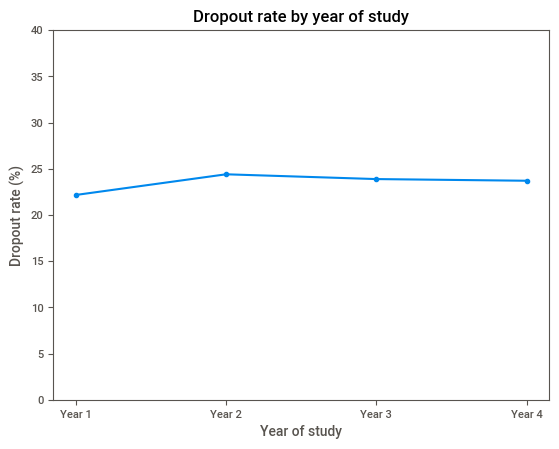

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
#Does dropout change from Year 1 to Year 4?
year = df_manual.groupby("Year_of_Study")["Dropout"].mean() * 100

plt.plot(year.index, year.values, marker="o")
plt.title("Dropout rate by year of study")
plt.xlabel("Year of study")
plt.ylabel("Dropout rate (%)")
plt.ylim(0, 40)
plt.savefig("q3_line_year.png")
plt.show()

files.download("q3_line_year.png")

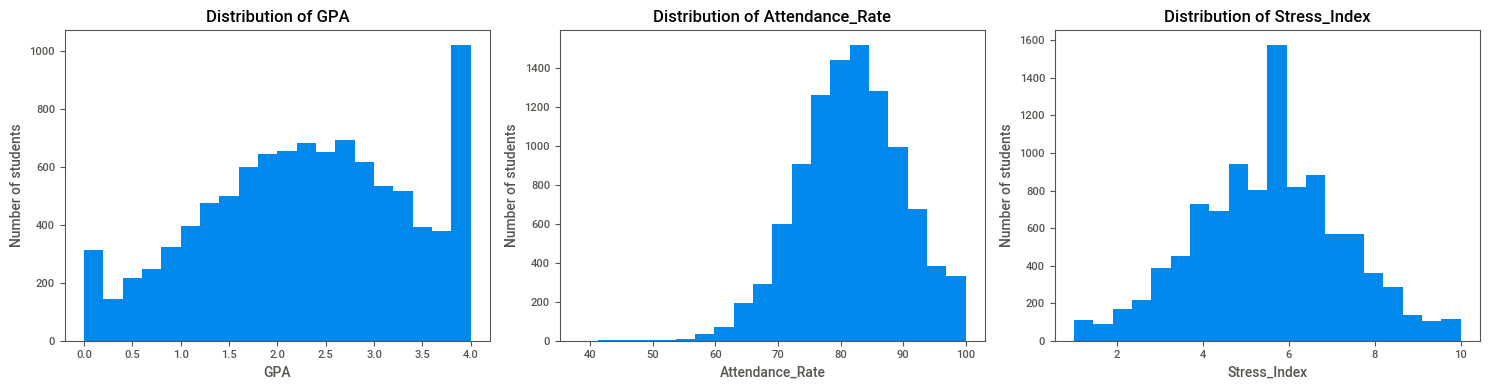

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
#How are GPA, attendance and stress spread across students?
#histograms of GPA, attendance and stress
cols = ["GPA", "Attendance_Rate", "Stress_Index"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, cols):
    ax.hist(df_manual[col], bins=20)
    ax.set_title("Distribution of " + col)
    ax.set_xlabel(col)
    ax.set_ylabel("Number of students")

plt.tight_layout()
plt.savefig("q4_histograms.png")
plt.show()

files.download("q4_histograms.png")

/tmp/ipykernel_935/2448818796.py:12: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Stayed", "Dropped out"])
/tmp/ipykernel_935/2448818796.py:12: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Stayed", "Dropped out"])


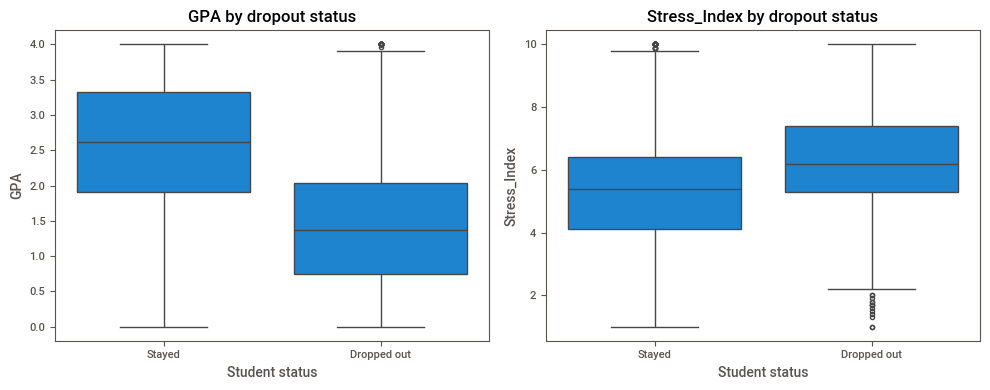

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
#Do dropout students have lower GPA and higher stress?
#box plots of GPA and Stress_Index by dropout status
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, col in zip(axes, ["GPA", "Stress_Index"]):
    sns.boxplot(x="Dropout", y=col, data=df_manual, ax=ax)
    ax.set_title(col + " by dropout status")
    ax.set_xlabel("Student status")
    ax.set_ylabel(col)
    ax.set_xticklabels(["Stayed", "Dropped out"])

plt.tight_layout()
plt.savefig("q5_boxplots.png")
plt.show()

files.download("q5_boxplots.png")

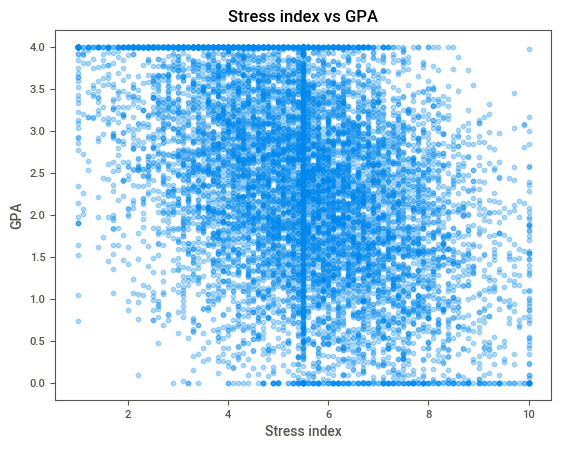

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
#Is higher stress linked to lower GPA?
#scatter plot of Stress_Index against GPA
plt.scatter(df_manual["Stress_Index"], df_manual["GPA"], alpha=0.3, s=10)
plt.title("Stress index vs GPA")
plt.xlabel("Stress index")
plt.ylabel("GPA")
plt.savefig("q6_scatter_stress_gpa.png")
plt.show()

files.download("q6_scatter_stress_gpa.png")

304
       Stress_Index     GPA  Attendance_Rate
count        304.00  304.00           304.00
mean           5.64    2.29            82.21
std            1.69    1.07             8.40
min            1.00    0.00            38.20
25%            4.70    1.47            77.57
50%            5.55    2.27            82.50
75%            6.70    3.12            87.80
max           10.00    4.00           100.00


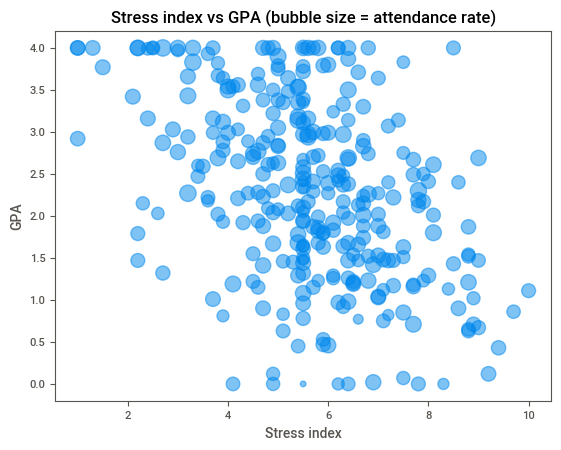

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
#Do attendance and stress together relate to GPA?
bubble_df = df_manual.iloc[::33]

print(len(bubble_df))
print(bubble_df[["Stress_Index", "GPA", "Attendance_Rate"]].describe().round(2))

plt.scatter(bubble_df["Stress_Index"], bubble_df["GPA"],
            s=(bubble_df["Attendance_Rate"] - 30) * 2, alpha=0.5)
plt.title("Stress index vs GPA (bubble size = attendance rate)")
plt.xlabel("Stress index")
plt.ylabel("GPA")
plt.savefig("q7_bubble_v3.png")
plt.show()

files.download("q7_bubble_v3.png")

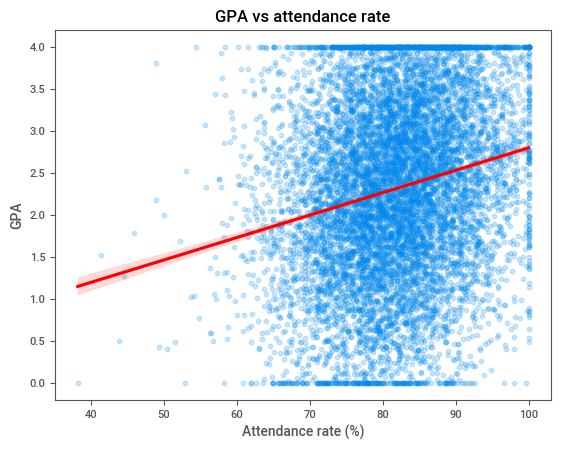

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
#Does GPA rise with attendance?
#regression plot of GPA against attendance
import seaborn as sns

sns.regplot(x="Attendance_Rate", y="GPA", data=df_manual,
            scatter_kws={"alpha": 0.2, "s": 10}, line_kws={"color": "red"})
plt.title("GPA vs attendance rate")
plt.xlabel("Attendance rate (%)")
plt.ylabel("GPA")
plt.savefig("q8_regression.png")
plt.show()

files.download("q8_regression.png")

/tmp/ipykernel_935/1955358211.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  level = df_manual.groupby("Attendance_Level")["Dropout"].mean().reindex(["Low", "Medium", "High"]) * 100


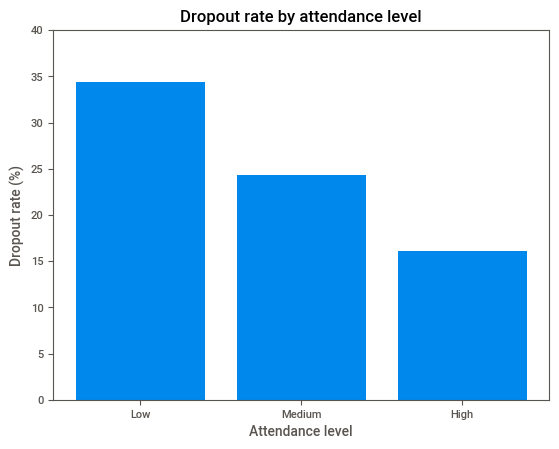

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
#Does dropout rise as attendance falls?
#bar chart of dropout rate by attendance level
level = df_manual.groupby("Attendance_Level")["Dropout"].mean().reindex(["Low", "Medium", "High"]) * 100

plt.bar(level.index, level.values)
plt.title("Dropout rate by attendance level")
plt.xlabel("Attendance level")
plt.ylabel("Dropout rate (%)")
plt.ylim(0, 40)
plt.savefig("q9_bar_attendance.png")
plt.show()

files.download("q9_bar_attendance.png")

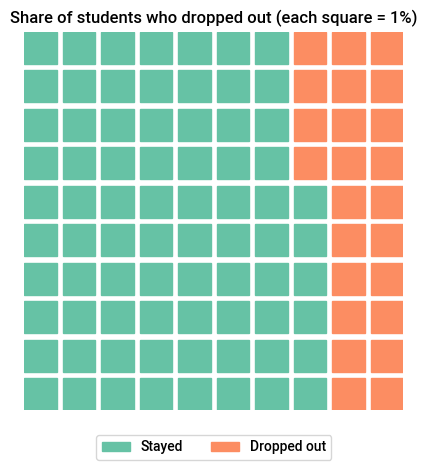

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
#install and draw the waffle chart
!pip install pywaffle -q

from pywaffle import Waffle
from google.colab import files
import matplotlib.pyplot as plt

counts = df_manual["Dropout"].value_counts().sort_index()

plt.figure(FigureClass=Waffle, rows=10, columns=10,
           values=counts.values,
           labels=["Stayed", "Dropped out"],
           legend={"loc": "lower center", "bbox_to_anchor": (0.5, -0.15), "ncol": 2})
plt.title("Share of students who dropped out (each square = 1%)")
plt.savefig("q1_waffle.png", bbox_inches="tight")
plt.show()

files.download("q1_waffle.png")

In [ ]:
#run AutoViz on your data
!pip install autoviz -q

from autoviz.AutoViz_Class import AutoViz_Class

AV = AutoViz_Class()
report = AV.AutoViz(filename="", dfte=df_manual, depVar="Dropout", verbose=1)

Shape of your Data Set loaded: (10000, 20)
#######################################################################################
######################## C L A S S I F Y I N G  V A R I A B L E S  ####################
#######################################################################################
Classifying variables in data set...
    Number of Numeric Columns =  9
    Number of Integer-Categorical Columns =  1
    Number of String-Categorical Columns =  3
    Number of Factor-Categorical Columns =  1
    Number of String-Boolean Columns =  4
    Number of Numeric-Boolean Columns =  0
    Number of Discrete String Columns =  0
    Number of NLP String Columns =  0
    Number of Date Time Columns =  0
    Number of ID Columns =  1
    Number of Columns to Delete =  0
    19 Predictors classified...
        1 variable(s) removed since they were ID or low-information variables
        List of variables removed: ['Student_ID']

################ Binary_Classification problem ####

,Data Type,Missing Values%,Unique Values%,Minimum Value,Maximum Value,DQ Issue
Age,float64,0.000000,NA,17.000000,29.600000,Column has 33 outliers greater than upper bound (27.00) or lower than lower bound(15.00). Cap them or remove them.
Gender,object,0.000000,0,,,No issue
Family_Income,float64,0.000000,NA,25000.000000,70904.375000,No issue
Internet_Access,object,0.000000,0,,,No issue
Study_Hours_per_Day,float64,0.000000,NA,0.500000,8.980000,Column has 138 outliers greater than upper bound (7.21) or lower than lower bound(0.81). Cap them or remove them.
Attendance_Rate,float64,0.000000,NA,38.200000,100.000000,Column has 57 outliers greater than upper bound (103.65) or lower than lower bound(60.05). Cap them or remove them.
Assignment_Delay_Days,int64,0.000000,0,0.000000,8.000000,Column has 25 outliers greater than upper bound (6.00) or lower than lower bound(-2.00). Cap them or remove them.
Travel_Time_Minutes,float64,0.000000,NA,5.000000,74.900000,Column has 25 outliers greater than upper bound (63.15) or lower than lower bound(-2.85). Cap them or remove them.
Part_Time_Job,object,0.000000,0,,,No issue
Scholarship,object,0.000000,0,,,No issue


Total Number of Scatter Plots = 45
All Plots done
Time to run AutoViz = 24 seconds 

 ###################### AUTO VISUALIZATION Completed ########################
